scale = 0.4909 arcsec/pix | source_3: 7820 events | all photons: 68764 events
center (all-photon centroid within 1.5") = (4096.00, 4096.12) pix

=== OBSERVED FWHM (arcsec) ===
                                                      E-W          N-S       radial
This work: all photons                         1.39±0.02   1.19±0.02   1.29±0.01   (n=25852)
This work: source_3 only                       1.52±0.01   1.35±0.01   1.42±0.01   (n=7820)
Baganoff+03: Sgr A* (observed)                 1.60          1.30
Baganoff+03: comparison point source 1         1.10          1.00
Baganoff+03: comparison point source 2         0.90          0.90
Chandra on-axis PSF (Baganoff+03)              0.50          0.50

=== INTRINSIC SIZE = sqrt(observed^2 - PSF^2), mean of E-W and N-S (arcsec) ===
This work: all photons             PSF = on-axis PSF 0.5"                                           -> 1.19"
This work: all photons             PSF = point-source mean 0.975" (Baganoff's comparison sources)   -

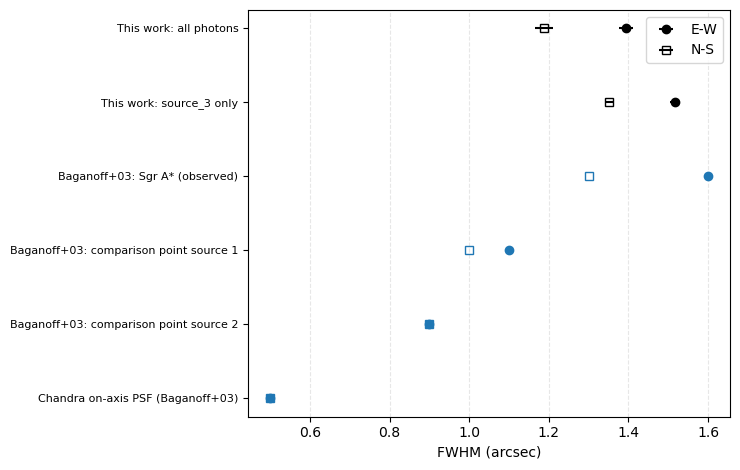

In [41]:
#!/usr/bin/env python
"""Compare the width of Sgr A* in your data with published Chandra widths.

Fits (a) an axis-aligned 2D Gaussian + constant (E-W / N-S, as in Baganoff+03) and
(b) a radial Gaussian + constant, to ALL photons and to source_3 only, with bootstrap errors.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import minimize, curve_fit

# ============================================================================ config
MERGED_FILE = "separate_and_stack/output/merged/merged_source_3.fits"
LABELS_FILE = "models/merged_labels.parquet"   # all photons in the box
OUTDIR      = "output"

SCALE  = 0.5 * (1.363719695301011e-4 + 1.3637196953011839e-4) * 3600.0     # arcsec / pix (~0.4909)
WIN    = 4.0       # arcsec, half-size of the fit window (box edge is only ~5.4" from the center)
BIN    = 0.25      # arcsec, histogram bin for the 2D fit
N_BOOT = 100       # bootstrap resamples for the errors
SEED   = 1
FWHM_K = 2 * np.sqrt(2 * np.log(2))                                        # sigma -> FWHM

# ---- published numbers (arcsec FWHM). x ~ E-W, y ~ N-S in sky coordinates ----
# Baganoff+03 values below are from the 2001 preprint text (section 5.2); check the ApJ version.
LIT_OBS = [
    # label,                                       E-W,  N-S
    ("Baganoff+03: Sgr A* (observed)",              1.6,  1.3),
    ("Baganoff+03: comparison point source 1",      1.1,  1.0),
    ("Baganoff+03: comparison point source 2",      0.9,  0.9),
    ("Chandra on-axis PSF (Baganoff+03)",           0.5,  0.5),
]
LIT_INTRINSIC = [
    ("Baganoff+03 published intrinsic size",        1.4),
    ("Baganoff+03 preprint intrinsic size",         1.0),
    ("Wang+13 (quotes Baganoff's size)",            1.4),
]
PSF_REFS = {   # reference widths used to subtract the PSF in quadrature (arcsec FWHM)
    "on-axis PSF 0.5\"": 0.5,
    "point-source mean 0.975\" (Baganoff's comparison sources)": np.mean([1.1, 0.9, 1.0, 0.9]),
}

# ============================================================================ data
def load_events(path):
    with fits.open(path) as h:
        d = h["EVENTS"].data
        return pd.DataFrame({c: np.asarray(d[c], float) for c in ("x", "y", "energy")})

src3 = load_events(MERGED_FILE)
allp = pd.read_parquet(LABELS_FILE)[["x", "y", "energy"]].astype(float)
print(f"scale = {SCALE:.4f} arcsec/pix | source_3: {len(src3)} events | all photons: {len(allp)} events")

def refine_center(tab, start, radius_as=1.5, n_iter=8):
    c = np.array(start, float)
    for _ in range(n_iter):
        d = np.hypot(tab["x"] - c[0], tab["y"] - c[1]) * SCALE
        m = d < radius_as
        c = np.array([tab["x"][m].mean(), tab["y"][m].mean()])
    return tuple(c)

CENTER = refine_center(allp, (np.median(src3["x"]), np.median(src3["y"])))
print(f"center (all-photon centroid within 1.5\") = ({CENTER[0]:.2f}, {CENTER[1]:.2f}) pix")

# ============================================================================ 2D Gaussian + constant
def _hist(dx, dy):
    e = np.arange(-WIN, WIN + BIN, BIN)
    n = np.histogram2d(dx, dy, bins=[e, e])[0]
    c = 0.5 * (e[1:] + e[:-1])
    XC, YC = np.meshgrid(c, c, indexing="ij")
    return n, XC, YC

def _nll(p, n, XC, YC):
    A, x0, y0, sx, sy, C = p
    mu = A * np.exp(-0.5 * (((XC - x0) / sx) ** 2 + ((YC - y0) / sy) ** 2)) + C
    mu = np.maximum(mu, 1e-9)
    return np.sum(mu - n * np.log(mu))                      # Poisson negative log-likelihood

def fit_gauss2d(dx, dy, p0=None):
    n, XC, YC = _hist(dx, dy)
    if p0 is None:
        outer = n[np.hypot(XC, YC) > 0.75 * WIN]
        p0 = [max(n.max() - outer.mean(), 1.0), 0.0, 0.0, 0.6, 0.6, max(outer.mean(), 1e-3)]
    bounds = [(0, None), (-1.5, 1.5), (-1.5, 1.5), (0.1, 3.0), (0.1, 3.0), (0, None)]
    r = minimize(_nll, p0, args=(n, XC, YC), method="L-BFGS-B", bounds=bounds)
    return r.x

def width_2d(tab, center, n_boot=N_BOOT):
    dx = (tab["x"].values - center[0]) * SCALE
    dy = (tab["y"].values - center[1]) * SCALE
    m = (np.abs(dx) < WIN) & (np.abs(dy) < WIN)
    dx, dy = dx[m], dy[m]
    best = fit_gauss2d(dx, dy)
    rng = np.random.default_rng(SEED)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(dx), len(dx))
        boots.append(fit_gauss2d(dx[i], dy[i], p0=best))
    boots = np.array(boots)
    fw = lambda p: np.array([FWHM_K * p[3], FWHM_K * p[4]])             # (E-W, N-S)
    fw_best = fw(best)
    fw_err = np.std([fw(b) for b in boots], axis=0)
    return fw_best, fw_err, best, len(dx)

# ============================================================================ radial Gaussian + constant
def width_radial(tab, center):
    d = np.hypot(tab["x"] - center[0], tab["y"] - center[1]).values * SCALE
    edges = np.arange(0, WIN + 1e-9, 0.25)
    n = np.histogram(d, bins=edges)[0].astype(float)
    area = np.pi * (edges[1:] ** 2 - edges[:-1] ** 2) / SCALE ** 2          # px^2
    r = 0.5 * (edges[1:] + edges[:-1])
    y, err = n / area, np.sqrt(np.maximum(n, 1)) / area
    f = lambda r, N, s, C: N * np.exp(-r ** 2 / (2 * s ** 2)) + C
    p, c = curve_fit(f, r, y, sigma=err, absolute_sigma=True,
                     p0=[y[0] - y[-1], 0.7, y[-1]], bounds=([0, 0.1, 0], [np.inf, 3, np.inf]))
    return FWHM_K * abs(p[1]), FWHM_K * np.sqrt(c[1, 1])

def intrinsic(obs, psf):
    return float(np.sqrt(max(obs ** 2 - psf ** 2, 0.0)))

# ============================================================================ run
results = {}
for name, tab in [("This work: all photons", allp), ("This work: source_3 only", src3)]:
    fw, fe, best, nev = width_2d(tab, CENTER)
    rw, re = width_radial(tab, CENTER)
    results[name] = dict(ew=fw[0], ew_e=fe[0], ns=fw[1], ns_e=fe[1], rad=rw, rad_e=re,
                         mean=fw.mean(), n=nev, bg=best[5])

print("\n=== OBSERVED FWHM (arcsec) ===")
print(f"{'':44s} {'E-W':>12s} {'N-S':>12s} {'radial':>12s}")
for k, v in results.items():
    print(f"{k:44s} {v['ew']:6.2f}±{v['ew_e']:4.2f} {v['ns']:6.2f}±{v['ns_e']:4.2f} "
          f"{v['rad']:6.2f}±{v['rad_e']:4.2f}   (n={v['n']})")
for lab_, ew, ns in LIT_OBS:
    print(f"{lab_:44s} {ew:6.2f}        {ns:6.2f}")

print("\n=== INTRINSIC SIZE = sqrt(observed^2 - PSF^2), mean of E-W and N-S (arcsec) ===")
for k, v in results.items():
    for pname, psf in PSF_REFS.items():
        print(f"{k:34s} PSF = {pname:58s} -> {intrinsic(v['mean'], psf):.2f}\"")
print("\nPublished intrinsic sizes:")
for lab_, s in LIT_INTRINSIC:
    print(f"  {lab_:40s} {s:.1f}\"")

# sanity check of the method on Baganoff's own numbers (should give ~1")
bag_sgra = np.mean([1.6, 1.3]); bag_ref = PSF_REFS[list(PSF_REFS)[1]]
print(f"\nCheck: Baganoff's observed widths with his method -> {intrinsic(bag_sgra, bag_ref):.2f}\" (preprint says ~1\")")

# ============================================================================ plot
fig, ax = plt.subplots(figsize=(7.5, 4.8))
rows, ypos = [], 0
for k, v in results.items():
    rows.append((k, v["ew"], v["ew_e"], v["ns"], v["ns_e"], "k"))
for lab_, ew, ns in LIT_OBS:
    rows.append((lab_, ew, 0, ns, 0, "tab:blue"))
for i, (lab_, ew, ew_e, ns, ns_e, col) in enumerate(rows):
    ax.errorbar(ew, i, xerr=ew_e, fmt="o", color=col, ms=6, label="E-W" if i == 0 else None)
    ax.errorbar(ns, i, xerr=ns_e, fmt="s", color=col, mfc="none", ms=6, label="N-S" if i == 0 else None)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("FWHM (arcsec)"); ax.grid(axis="x", ls="--", alpha=0.3)
ax.legend(); plt.tight_layout()
plt.savefig(f"{OUTDIR}/width_comparison.png", dpi=150)
plt.show()
